# 04 - Explicabilidade com SHAP

Objetivos:
- **Global:** quais variáveis mais influenciam o churn na população?
- **Local:** por que um cliente específico está em risco? (alimenta o dashboard e o carteirização
  do time de retenção com "motivo").


In [1]:
%matplotlib inline
import sys, pathlib, os
ROOT = pathlib.Path(os.getcwd())
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110

import features as fe
import business as bz
import train as T

RAW = ROOT / "data" / "raw" / "BankChurners.csv"
ART = ROOT / "artifacts"
FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)


In [2]:
import shap, json, joblib

raw = T.load_raw(RAW)
X, feature_columns = fe.build_features(raw)
y = (raw[fe.TARGET_COLUMN].astype(str).str.strip() == fe.TARGET_POSITIVE).astype(int).reset_index(drop=True)
X = X.reset_index(drop=True)

medians = json.loads((ART / "medians.json").read_text())
model = joblib.load(ART / "churn_model.pkl")
X_fit = fe.impute_medians(X, medians)

explainer = shap.TreeExplainer(model)
sv = explainer.shap_values(X_fit)   # (n, n_features)
print("shap_values:", sv.shape)


shap_values: (10127, 32)


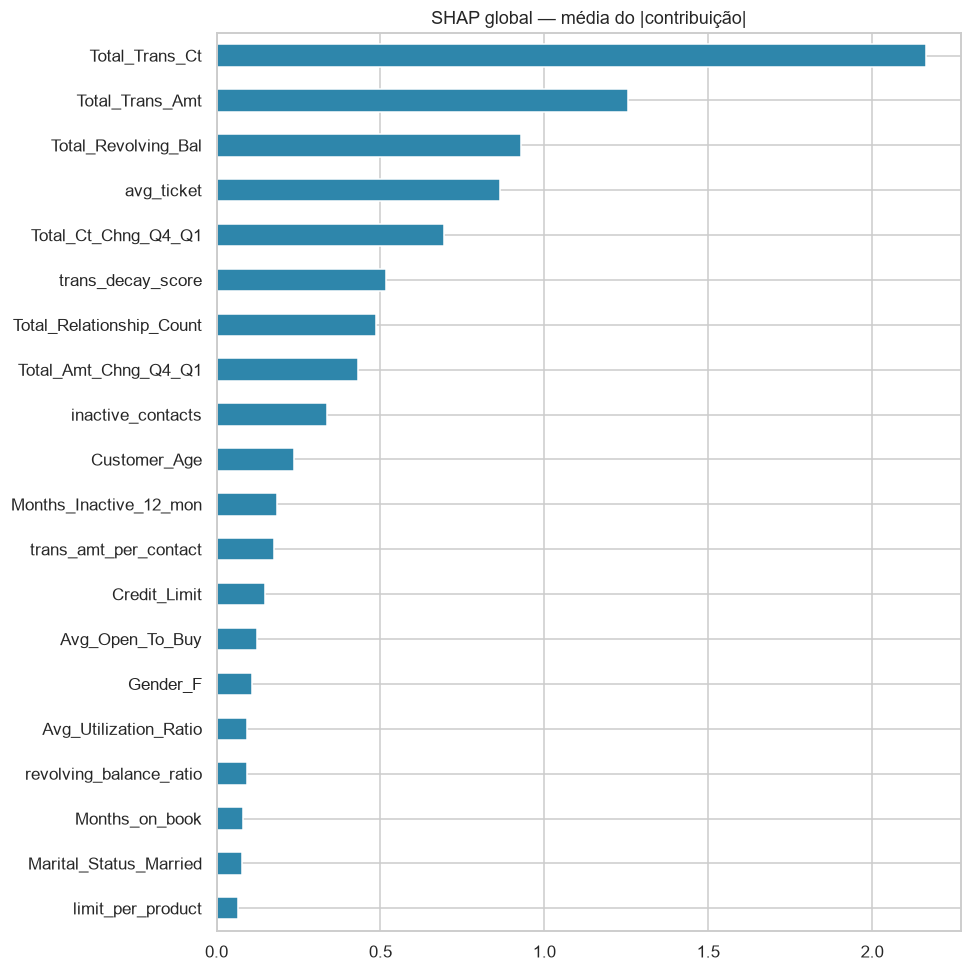

In [3]:
# SHAP global — importância média absoluta
mean_abs = np.abs(sv).mean(axis=0)
imp = pd.Series(mean_abs, index=feature_columns).sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(9, 9))
imp.tail(20).plot.barh(ax=ax, color="#2e86ab")
ax.set_title("SHAP global — média do |contribuição|")
plt.tight_layout()
plt.savefig(FIG / "shap_global_bar.png", bbox_inches="tight")
plt.show()


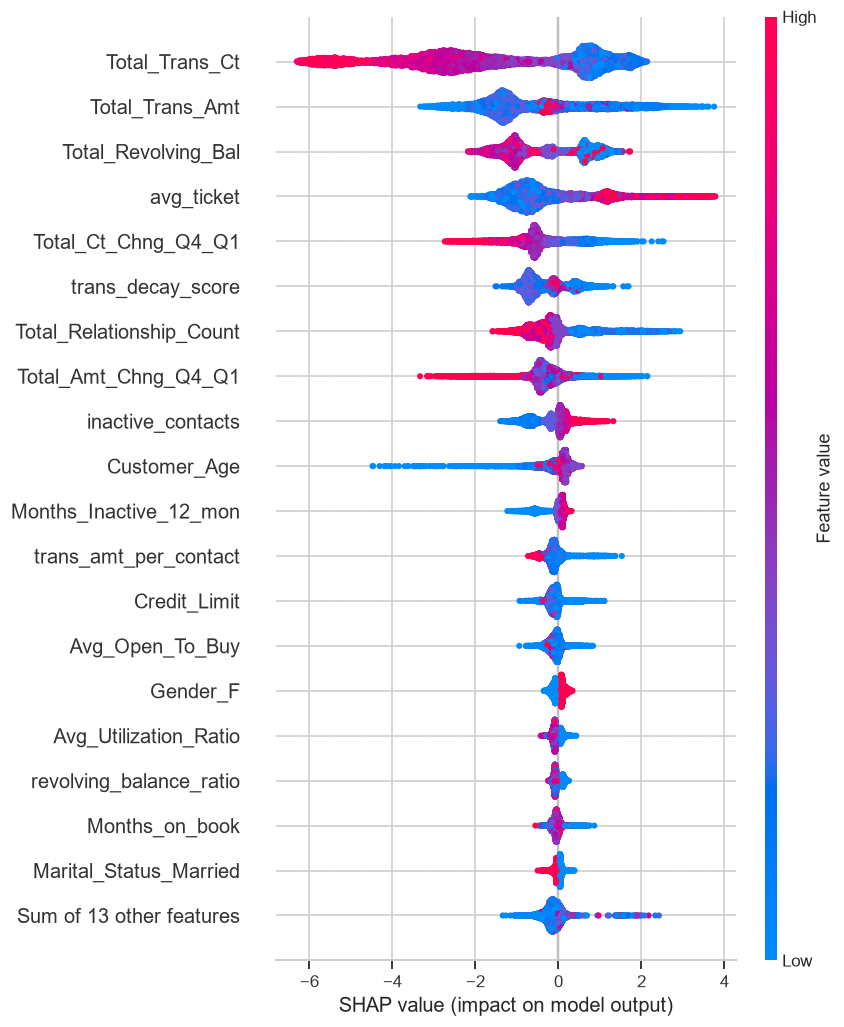

In [4]:
# SHAP global — resumo (beeswarm)
shap.plots.beeswarm(shap.Explanation(values=sv, base_values=explainer.expected_value,
                                      data=X_fit.values, feature_names=feature_columns),
                    max_display=20, show=False)
plt.tight_layout()
plt.savefig(FIG / "shap_summary.png", bbox_inches="tight")
plt.show()


In [5]:
# SHAP local — os clientes de maior risco e o "porquê" de cada um
drivers = json.loads((ART / "shap_local.json").read_text())
demo = pd.read_csv(ROOT / "data" / "processed" / "churn_scores_demo.csv")
top = demo.sort_values("score_churn", ascending=False).head(8)

for _, row in top.iterrows():
    d = drivers.get(str(row.name), drivers.get(row.name, None))
    if d is None:
        continue
    motivo = " + ".join([f"{x['feature']} {x['values']:+.3f}" for x in d["pressiona_churn"]])
    print(f"Cliente {int(row['id_cliente'])} · score {row['score_churn']:.3f} · {row['segmento']}")
    print(f"   Principais motivos: {motivo[:120]}")


Cliente 712660308 · score 1.000 · acao_automatizada
   Principais motivos: Total_Trans_Amt +2.237 + Total_Trans_Ct +1.928 + Total_Relationship_Count +1.393
Cliente 779183958 · score 1.000 · acao_automatizada
   Principais motivos: Total_Trans_Amt +1.817 + Total_Trans_Ct +1.798 + Total_Relationship_Count +1.486
Cliente 714602658 · score 1.000 · acao_automatizada
   Principais motivos: Total_Relationship_Count +1.687 + Total_Trans_Ct +1.365 + Total_Amt_Chng_Q4_Q1 +1.267
Cliente 711800658 · score 1.000 · acao_automatizada
   Principais motivos: Total_Trans_Amt +2.006 + Total_Trans_Ct +1.934 + Total_Relationship_Count +1.382
Cliente 719770158 · score 1.000 · acao_automatizada
   Principais motivos: Total_Trans_Ct +1.919 + Total_Relationship_Count +1.621 + Total_Trans_Amt +1.323
Cliente 720190083 · score 1.000 · acao_automatizada
   Principais motivos: Total_Trans_Amt +1.929 + Total_Relationship_Count +1.710 + Total_Trans_Ct +1.642
Cliente 718148358 · score 1.000 · acao_automatizada
   Prin

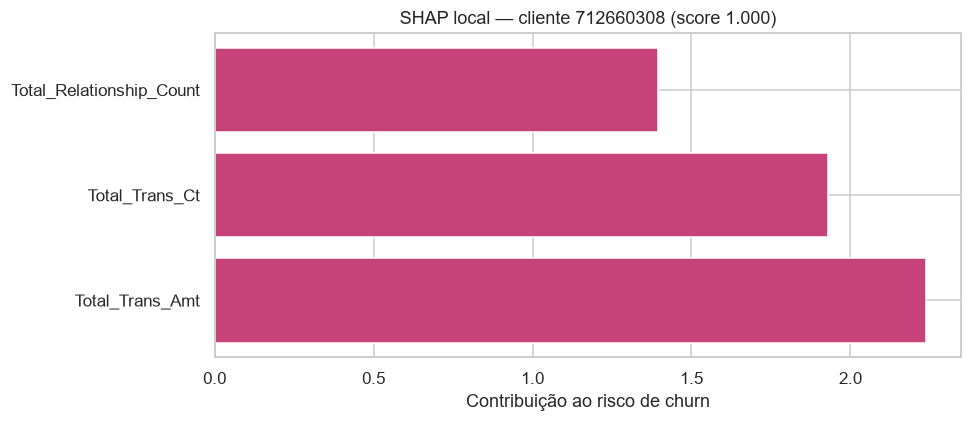

In [6]:
# Visualização local de um cliente específico (maior score da base)
i = int(top.index[0])
d = drivers[str(i)] if str(i) in drivers else drivers[i]
labels = [x["feature"] for x in (d["pressiona_churn"] + d["protege_churn"])]
vals = [x["values"] for x in (d["pressiona_churn"] + d["protege_churn"])]
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(labels, vals, color=["#c7417b" if v > 0 else "#2e86ab" for v in vals])
ax.set_title(f"SHAP local — cliente {int(top.iloc[0]['id_cliente'])} (score {top.iloc[0]['score_churn']:.3f})")
ax.set_xlabel("Contribuição ao risco de churn")
plt.tight_layout()
plt.savefig(FIG / "shap_local_exemplo.png", bbox_inches="tight")
plt.show()


### Interpretação

- **Inatividade** e **contatos com o SAC** empurram consistentemente o risco para cima;
  **alcance de transações** (valor e quantidade) protege.
- O **limite não utilizado** (`Avg_Open_To_Buy`) aparece como sinal de risco quando alto
  (teto que o cliente não usa) — reforça a ideia de "produto subutilizado".
- Para a operação: o dashboard mostra o **motivo** de cada cliente em risco, permitindo
  personalizar a oferta (ex.: reativar o usuário ocioso vs. resolver problema de cobrança).
